In [8]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/project

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/project


In [9]:
import glob, os, zipfile

for act in ["walking", "standing", "jumping", "still"]:
    for z in sorted(glob.glob(f"zips_{act}/*.zip")):
        out = f"exports_{act}/" + os.path.splitext(os.path.basename(z))[0]
        zipfile.ZipFile(z).extractall(out)
    print(act, len(glob.glob(f"exports_{act}/*")), "recordings")

walking 15 recordings
standing 15 recordings
jumping 15 recordings
still 15 recordings


In [10]:
!python convert_sensorlogger.py exports_walking gabriel walking
!python convert_sensorlogger.py exports_standing gabriel standing
!python convert_sensorlogger.py exports_jumping gabriel jumping
!python convert_sensorlogger.py exports_still gabriel still

exports_walking/gabriel_walking_01 -> data/train/walking/gabriel_walking_01.csv  (733 rows, 99.4 Hz)
exports_walking/gabriel_walking_02 -> data/train/walking/gabriel_walking_02.csv  (777 rows, 98.8 Hz)
exports_walking/gabriel_walking_03 -> data/train/walking/gabriel_walking_03.csv  (708 rows, 98.7 Hz)
exports_walking/gabriel_walking_04 -> data/train/walking/gabriel_walking_04.csv  (694 rows, 98.7 Hz)
exports_walking/gabriel_walking_05 -> data/train/walking/gabriel_walking_05.csv  (712 rows, 98.8 Hz)
exports_walking/gabriel_walking_06 -> data/train/walking/gabriel_walking_06.csv  (722 rows, 98.8 Hz)
exports_walking/gabriel_walking_07 -> data/train/walking/gabriel_walking_07.csv  (707 rows, 98.8 Hz)
exports_walking/gabriel_walking_08 -> data/train/walking/gabriel_walking_08.csv  (718 rows, 98.7 Hz)
exports_walking/gabriel_walking_09 -> data/train/walking/gabriel_walking_09.csv  (720 rows, 98.7 Hz)
exports_walking/gabriel_walking_10 -> data/train/walking/gabriel_walking_10.csv  (713 rows,

In [11]:
!ls -la exports_walking/gabriel_walking_01
!head -3 exports_walking/gabriel_walking_01/*.csv

total 145
drwx------  2 root root  4096 Oct 27 18:59 .
drwx------ 17 root root  4096 Oct 27 18:54 ..
-rw-------  1 root root     0 Oct 27 18:59 Accelerometer.csv
-rw-------  1 root root 68576 Oct 27 18:59 AccelerometerUncalibrated.csv
-rw-------  1 root root     0 Oct 27 18:59 Annotation.csv
-rw-------  1 root root     0 Oct 27 18:59 Gyroscope.csv
-rw-------  1 root root 70963 Oct 27 18:59 GyroscopeUncalibrated.csv
-rw-------  1 root root   371 Oct 27 18:59 Metadata.csv
==> exports_walking/gabriel_walking_01/Accelerometer.csv <==

==> exports_walking/gabriel_walking_01/AccelerometerUncalibrated.csv <==
time,seconds_elapsed,z,y,x
1793114015459648500,0.0036484375,-0.8282318115234375,-0.4228973388671875,-0.1016082763671875
1793114015469712600,0.013712646484375,-0.8144378662109375,-0.4312286376953125,-0.111053466796875

==> exports_walking/gabriel_walking_01/Annotation.csv <==

==> exports_walking/gabriel_walking_01/Gyroscope.csv <==

==> exports_walking/gabriel_walking_01/GyroscopeUncalib

In [12]:
!ls data/train/walking
!head -3 data/train/walking/gabriel_walking_01.csv
!ls data/train/standing | wc -l
!ls data/train/jumping | wc -l
!ls data/train/still | wc -l

gabriel_walking_01.csv	gabriel_walking_06.csv	gabriel_walking_11.csv
gabriel_walking_02.csv	gabriel_walking_07.csv	gabriel_walking_12.csv
gabriel_walking_03.csv	gabriel_walking_08.csv	gabriel_walking_13.csv
gabriel_walking_04.csv	gabriel_walking_09.csv	gabriel_walking_14.csv
gabriel_walking_05.csv	gabriel_walking_10.csv	gabriel_walking_15.csv
timestamp,ax,ay,az,gx,gy,gz
0.0036484375,-0.1016082763671875,-0.4228973388671875,-0.8282318115234375,0.0573596954345703,0.0631150528788566,-0.0329422354698181
0.013712646484375,-0.111053466796875,-0.4312286376953125,-0.8144378662109375,-0.0033673932487378946,0.13206671905597958,-0.058084485586992404
15
15
15


In [13]:
import glob, os, zipfile
for z in sorted(glob.glob("zips_test/*.zip")):
    zipfile.ZipFile(z).extractall("exports_test/" + os.path.splitext(os.path.basename(z))[0])
!ls exports_test

session1  session2


In [14]:
!python convert_sensorlogger.py exports_test gabriel test --test
!mv data/test/gabriel_test_01.csv data/test/session1.csv
!mv data/test/gabriel_test_02.csv data/test/session2.csv

exports_test/session1 -> data/test/gabriel_test_01.csv  (4516 rows, 99.3 Hz)
exports_test/session2 -> data/test/gabriel_test_02.csv  (4472 rows, 99.4 Hz)


In [15]:
open("data/test/session1_labels.csv", "w").write("""start,end,label
3,11,standing
13,21,walking
23,31,jumping
35,43,still
""")
open("data/test/session2_labels.csv", "w").write("""start,end,label
3,11,walking
13,21,jumping
23,31,standing
35,43,still
""")

70

In [16]:
!ls data/test
!head -3 data/test/session1.csv

session1.csv  session1_labels.csv  session2.csv  session2_labels.csv
timestamp,ax,ay,az,gx,gy,gz
0.050693603515625,0.01953125,-0.2765045166015625,-0.9510498046875,0.9167771935462952,0.0891221538186073,-0.2147200256586074
0.060758544921875,0.0237884521484375,-0.30145263671875,-0.965972900390625,0.8198060141561426,0.12481810090144302,-0.24843661881011334


# Modeling Human Activity States with a Hidden Markov Model (from scratch, NumPy)

**Name:** Gabriel Tuyisingize Sezibera

### Expected repo layout
```
data/
  train/
    standing/  member1_standing_01.csv ...
    walking/   member1_walking_01.csv ...
    jumping/   ...
    still/     ...
  test/
    session1.csv            # continuous recording, activities performed one after another
    session1_labels.csv     # columns: start,end,label   (seconds from session start)
    session2.csv
    session2_labels.csv
```
Every CSV needs columns: `timestamp, ax, ay, az, gx, gy, gz` (timestamp in s, ms or ns - detected automatically).
File name convention: `<member>_<activity>_<nn>.csv` so the sampling rate per member can be reported.

## 1. Configuration and imports
**Window size logic.** All recordings are resampled to a common rate `TARGET_FS` (harmonising different phones).
A window of `WIN_SEC = 2 s` = `TARGET_FS x 2` samples is long enough to contain ~2-4 steps (walking ~1.8-2 Hz) and
2-4 jumps, so the FFT can resolve the periodic component (frequency resolution = 1/2 s = 0.5 Hz), yet short enough that
a window rarely straddles two activities. 50 % overlap doubles the number of observations without changing the time resolution.

In [17]:
import os, glob, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.fft import rfft, rfftfreq

np.random.seed(42)
DATA_DIR   = "data"
ACTIVITIES = ["standing", "walking", "jumping", "still"]   # hidden states Z
K          = len(ACTIVITIES)
SENSORS    = ["ax", "ay", "az", "gx", "gy", "gz"]

TARGET_FS  = 50          # Hz, common rate after resampling
WIN_SEC    = 2.0
OVERLAP    = 0.5
TRIM_SEC   = 0.5         # drop start/end of each file (tapping the phone, putting it down)
WIN  = int(WIN_SEC * TARGET_FS)
STEP = int(WIN * (1 - OVERLAP))
print(f"Window = {WIN} samples ({WIN_SEC}s), step = {STEP} samples")

Window = 100 samples (2.0s), step = 50 samples


## 2. Data loading, harmonising sampling rates, inventory

In [18]:
def load_recording(path):
    """Read a CSV, return (DataFrame resampled to TARGET_FS, original fs in Hz)."""
    df = pd.read_csv(path).sort_values("timestamp").drop_duplicates("timestamp")
    t = df["timestamp"].values.astype(float)
    dt = np.median(np.diff(t))
    scale = 1e9 if dt > 1e6 else (1e3 if dt > 0.5 else 1.0)    # ns / ms / s
    t = (t - t[0]) / scale
    orig_fs = 1.0 / np.median(np.diff(t))
    t_new = np.arange(TRIM_SEC, t[-1] - TRIM_SEC, 1.0 / TARGET_FS)   # linear interpolation onto a uniform grid
    out = pd.DataFrame({c: np.interp(t_new, t, df[c].values) for c in SENSORS})
    out.insert(0, "t", t_new)
    return out, orig_fs

train_files = []
for act in ACTIVITIES:
    for p in sorted(glob.glob(f"{DATA_DIR}/train/{act}/*.csv")):
        rec, fs0 = load_recording(p)
        member = os.path.basename(p).split("_")[0]
        train_files.append(dict(path=p, activity=act, member=member, orig_fs=fs0, rec=rec, dur=rec["t"].iloc[-1]-rec["t"].iloc[0]))
inv = pd.DataFrame([{k: v for k, v in d.items() if k != "rec"} for d in train_files])
print("Files per activity:\n", inv.groupby("activity").agg(files=("path","count"), total_seconds=("dur","sum")).round(1))
print("\nOriginal sampling rate per member (Hz) -> insert in report:")
print(inv.groupby("member")["orig_fs"].agg(["mean","min","max"]).round(1))

Files per activity:
           files  total_seconds
activity                      
jumping      15           96.0
standing     15           92.1
still        15           91.7
walking      15           93.8

Original sampling rate per member (Hz) -> insert in report:
         mean   min   max
member                   
gabriel  99.4  99.3  99.4


### Sample raw data (for the report)

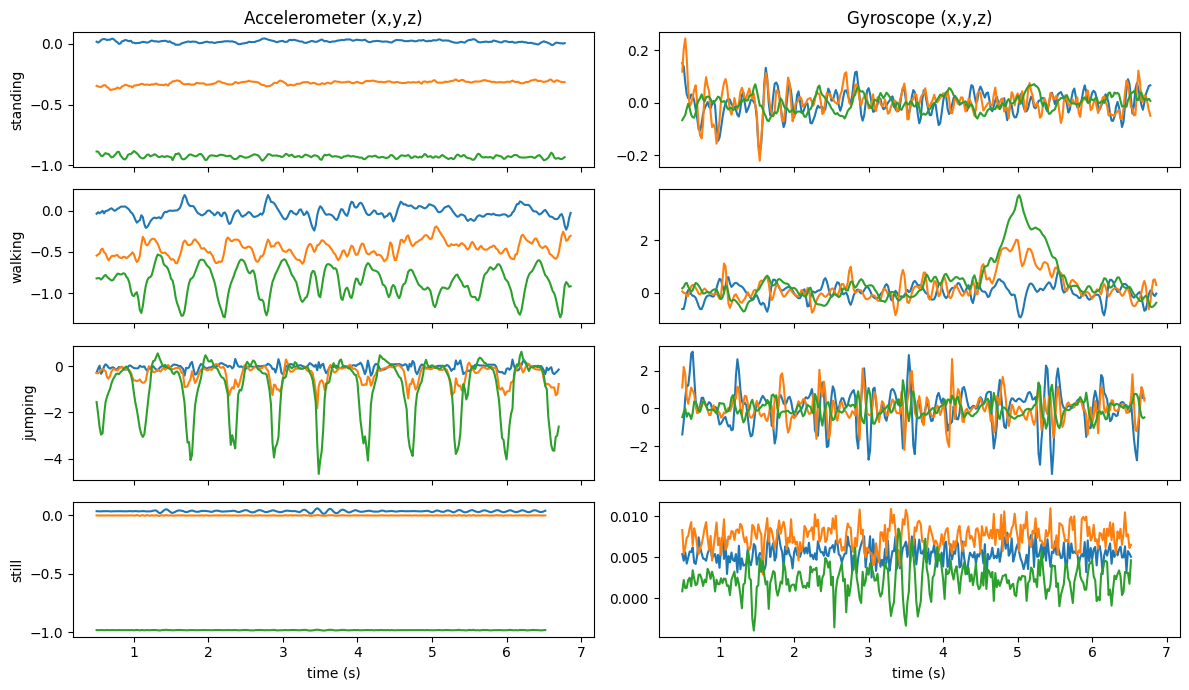

In [19]:
fig, axes = plt.subplots(K, 2, figsize=(12, 7), sharex=True)
for i, act in enumerate(ACTIVITIES):
    d = next(f for f in train_files if f["activity"] == act)["rec"]
    axes[i,0].plot(d["t"], d[["ax","ay","az"]]); axes[i,0].set_ylabel(act)
    axes[i,1].plot(d["t"], d[["gx","gy","gz"]])
axes[0,0].set_title("Accelerometer (x,y,z)"); axes[0,1].set_title("Gyroscope (x,y,z)")
axes[-1,0].set_xlabel("time (s)"); axes[-1,1].set_xlabel("time (s)")
plt.tight_layout(); plt.savefig("fig_raw_samples.png", dpi=150); plt.show()

## 3. Feature extraction (time + frequency domain)
Per window we compute 13 features from accelerometer and gyroscope (magnitude signals are orientation independent):

| Feature | Domain | Why it helps |
|---|---|---|
| `acc_mag_mean` | time | ~g when still; changes with phone orientation (standing at waist vs flat on table) |
| `acc_mag_std`, `acc_rms_dyn` | time | movement intensity: tiny for still/standing, moderate walking, large jumping |
| `acc_sma` | time | signal magnitude area of the gravity-removed signal; overall activity level |
| `acc_corr` | time | mean |correlation| between axes: coordinated motion in walking/jumping vs uncorrelated noise |
| `gyr_mag_mean`, `gyr_mag_std`, `gyr_sma` | time | rotation of the phone/hip (swing while walking, ~0 when still) |
| `acc_dom_freq`, `gyr_dom_freq` | freq (FFT) | cadence: walking ~1.5-2.5 Hz, jumping ~1-3 Hz with much higher energy |
| `acc_energy`, `gyr_energy` | freq (FFT) | spectral energy (Parseval) of the AC component |
| `acc_entropy` | freq (FFT) | periodic motion = peaked spectrum (low entropy), noise = flat spectrum (high entropy) |

**Normalisation:** energy/std/SMA features are strongly right-skewed (jumping is orders of magnitude above still), so
they are log-transformed to make a Gaussian emission reasonable, then **Z-score standardised using training statistics only**
(test data is transformed with the same mean/std to avoid leakage). Z-scoring puts features on a common scale so no single feature
dominates the Gaussian likelihood.

In [20]:
FEATURE_NAMES = ["acc_mag_mean","acc_mag_std","acc_rms_dyn","acc_sma","acc_corr",
                 "gyr_mag_mean","gyr_mag_std","gyr_sma",
                 "acc_dom_freq","acc_energy","acc_entropy","gyr_dom_freq","gyr_energy"]
LOG_FEATS = {"acc_mag_std","acc_rms_dyn","acc_sma","gyr_mag_mean","gyr_mag_std","gyr_sma","acc_energy","gyr_energy"}
LOG_IDX = [i for i, n in enumerate(FEATURE_NAMES) if n in LOG_FEATS]

def spectral_feats(sig, fs):
    """Dominant frequency, spectral energy, spectral entropy of a 1-D signal (Hann window + FFT)."""
    sig = sig - sig.mean()
    n = len(sig)
    spec = np.abs(rfft(sig * np.hanning(n))) ** 2
    freqs = rfftfreq(n, 1.0 / fs)
    spec[0] = 0.0
    tot = spec.sum()
    dom = freqs[np.argmax(spec)] if tot > 1e-12 else 0.0
    p = spec / (tot + 1e-12)
    entropy = -(p * np.log(p + 1e-12)).sum()
    return dom, tot / n, entropy

def window_features(w, fs=TARGET_FS):
    acc, gyr = w[:, :3], w[:, 3:]
    am, gm = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    acc_d = acc - acc.mean(0)
    c = np.nan_to_num(np.corrcoef(acc_d.T))
    corr = np.mean(np.abs([c[0,1], c[0,2], c[1,2]]))
    a_dom, a_en, a_ent = spectral_feats(am, fs)
    g_dom, g_en, _     = spectral_feats(gm, fs)
    return np.array([am.mean(), am.std(), np.sqrt((acc_d**2).sum(1).mean()),
                     np.abs(acc_d).sum(1).mean(), corr,
                     gm.mean(), gm.std(), np.abs(gyr).sum(1).mean(),
                     a_dom, a_en, a_ent, g_dom, g_en])

def featurize(rec):
    """Sliding windows -> raw feature matrix (n_windows, d) and window-centre times."""
    x = rec[SENSORS].values; t = rec["t"].values
    starts = range(0, len(x) - WIN + 1, STEP)
    X = np.array([window_features(x[s:s+WIN]) for s in starts])
    centres = np.array([t[s + WIN // 2] for s in starts])
    X[:, LOG_IDX] = np.log(X[:, LOG_IDX] + 1e-6)
    return X, centres

for f in train_files:
    f["X"], _ = featurize(f["rec"])
    f["y"] = np.full(len(f["X"]), ACTIVITIES.index(f["activity"]))

all_X = np.vstack([f["X"] for f in train_files])
MU, SD = all_X.mean(0), all_X.std(0) + 1e-9          # Z-score parameters, TRAIN ONLY
zscore = lambda X: (X - MU) / SD
for f in train_files: f["Z"] = zscore(f["X"])
print("Total training windows:", len(all_X), "| features:", all_X.shape[1])

Total training windows: 290 | features: 13


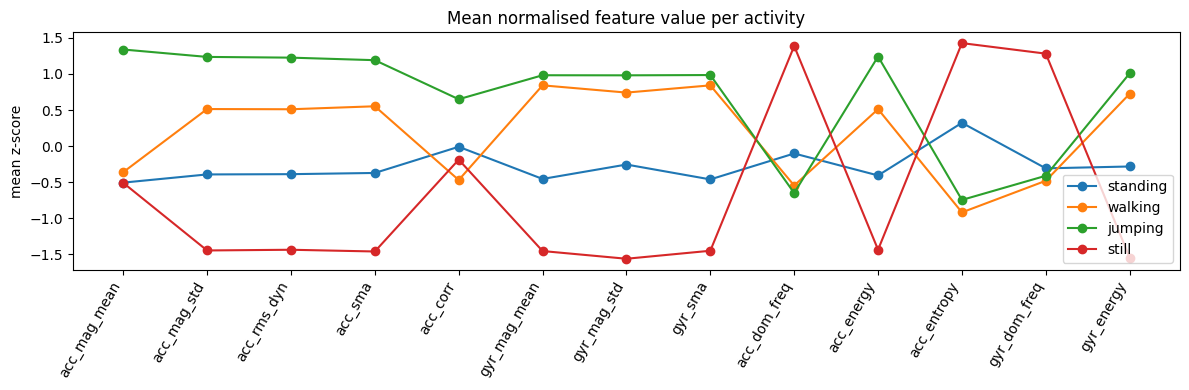

In [21]:
# Feature separability plot (for the report)
Zall = np.vstack([f["Z"] for f in train_files]); yall = np.concatenate([f["y"] for f in train_files])
fig, ax = plt.subplots(figsize=(12, 4))
for k, act in enumerate(ACTIVITIES):
    ax.plot(Zall[yall == k].mean(0), marker="o", label=act)
ax.set_xticks(range(len(FEATURE_NAMES))); ax.set_xticklabels(FEATURE_NAMES, rotation=60, ha="right")
ax.set_ylabel("mean z-score"); ax.legend(); ax.set_title("Mean normalised feature value per activity")
plt.tight_layout(); plt.savefig("fig_feature_means.png", dpi=150); plt.show()

## 4. HMM definition
* **Hidden states Z:** standing, walking, jumping, still (K = 4)
* **Observations X:** 13-dim z-scored feature vector per window
* **Emission B:** diagonal-covariance Gaussian per state, `b_j(x) = N(x | mu_j, diag(sigma_j^2))`
* **Transition A (4x4)**, **initial pi (4)**

**Algorithms and why (tied to the evaluation metrics):**
* **Viterbi** returns the single most likely state sequence; it is what produces the predictions behind the confusion matrix, sensitivity, specificity and accuracy.
* **Baum-Welch (EM)** learns A, B, pi by maximising the log-likelihood via the forward-backward algorithm; we stop when the log-likelihood improvement is below `tol` (not a fixed iteration count). It is initialised from the labelled data (supervised counts/means) so state *j* stays tied to activity *j*; EM then refines the parameters on all sequences.
* All computations are in **log-space** to avoid underflow.

In [22]:
def logsumexp(a, axis):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    return (m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))).squeeze(axis)

class GaussianHMM:
    def __init__(self, n_states, n_feat, var_floor=1e-2):
        self.K, self.D, self.floor = n_states, n_feat, var_floor
        self.pi = np.full(n_states, 1.0 / n_states)
        self.A = np.full((n_states, n_states), 1.0 / n_states)
        self.mu = np.zeros((n_states, n_feat)); self.var = np.ones((n_states, n_feat))
        self.ll_history = []

    # ---------- initialisation from labelled windows ----------
    def init_supervised(self, seqs, labels, smooth=1.0):
        pi = np.full(self.K, smooth); A = np.full((self.K, self.K), smooth)
        for y in labels:
            pi[y[0]] += 1
            for a, b in zip(y[:-1], y[1:]): A[a, b] += 1
        self.pi, self.A = pi / pi.sum(), A / A.sum(1, keepdims=True)
        X, Y = np.vstack(seqs), np.concatenate(labels)
        for k in range(self.K):
            self.mu[k] = X[Y == k].mean(0)
            self.var[k] = np.maximum(X[Y == k].var(0), self.floor)

    # ---------- emission log-probabilities ----------
    def log_emission(self, X):
        d = X[:, None, :] - self.mu[None]                       # (T,K,D)
        return -0.5 * (np.log(2 * np.pi * self.var)[None] + d**2 / self.var[None]).sum(-1)

    # ---------- forward-backward (log space) ----------
    def forward_backward(self, X):
        T = len(X); logB = self.log_emission(X)
        logA, logpi = np.log(self.A + 1e-300), np.log(self.pi + 1e-300)
        la = np.zeros((T, self.K)); lb = np.zeros((T, self.K))
        la[0] = logpi + logB[0]
        for t in range(1, T):
            la[t] = logsumexp(la[t-1][:, None] + logA, axis=0) + logB[t]
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t+1] + lb[t+1])[None, :], axis=1)
        ll = float(logsumexp(la[-1], axis=0))
        gamma = np.exp(la + lb - ll)
        xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll).sum(0)
        return gamma, xi, ll

    # ---------- Baum-Welch with convergence check ----------
    def baum_welch(self, seqs, tol=1e-3, max_iter=200, verbose=True):
        self.ll_history = []
        for it in range(max_iter):
            pi_n = np.zeros(self.K); A_n = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); x_sum = np.zeros((self.K, self.D)); x2_sum = np.zeros((self.K, self.D))
            total_ll = 0.0
            for X in seqs:                                                    # E-step
                g, xi, ll = self.forward_backward(X)
                total_ll += ll
                pi_n += g[0]; A_n += xi
                g_sum += g.sum(0); x_sum += g.T @ X; x2_sum += g.T @ (X**2)
            self.pi = pi_n / pi_n.sum()                                       # M-step
            self.A = (A_n + 1e-6) / (A_n + 1e-6).sum(1, keepdims=True)
            self.mu = x_sum / g_sum[:, None]
            self.var = np.maximum(x2_sum / g_sum[:, None] - self.mu**2, self.floor)
            self.ll_history.append(total_ll)
            if verbose and (it % 5 == 0): print(f"iter {it:3d}  log-lik = {total_ll:.3f}")
            if it > 0 and abs(total_ll - self.ll_history[-2]) < tol:
                print(f"Converged after {it+1} iterations (|dLL| < {tol}), final log-lik = {total_ll:.3f}")
                break
        return self

    # ---------- Viterbi ----------
    def viterbi(self, X):
        T = len(X); logB = self.log_emission(X)
        logA, logpi = np.log(self.A + 1e-300), np.log(self.pi + 1e-300)
        delta = np.zeros((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = logpi + logB[0]
        for t in range(1, T):
            scores = delta[t-1][:, None] + logA
            psi[t] = scores.argmax(0); delta[t] = scores.max(0) + logB[t]
        path = np.zeros(T, dtype=int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1): path[t] = psi[t+1, path[t+1]]
        return path

## 5. Training
Each training file contains a single activity, so a file alone has no transitions. We therefore build **composite training sequences** by
concatenating randomly ordered files (several shuffles), which gives the model realistic *switching* examples. Because the order is random,
the learned off-diagonal transition probabilities reflect the protocol, not natural behaviour - discuss this in the report.

iter   0  log-lik = 8216.030
Converged after 3 iterations (|dLL| < 0.001), final log-lik = 8216.277


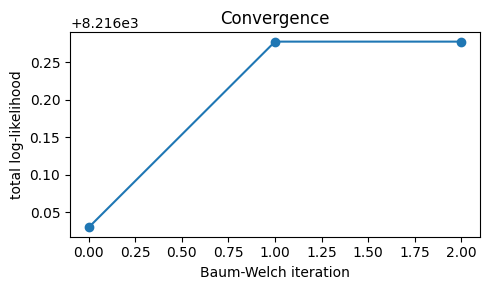

Training accuracy: 1.0


In [23]:
rng = np.random.default_rng(0)
def build_sequences(files, per_seq=8, rounds=6):
    seqs, labs = [], []
    for _ in range(rounds):
        idx = rng.permutation(len(files))
        for c in range(0, len(idx), per_seq):
            grp = [files[i] for i in idx[c:c+per_seq]]
            seqs.append(np.vstack([g["Z"] for g in grp])); labs.append(np.concatenate([g["y"] for g in grp]))
    return seqs, labs

seqs, labs = build_sequences(train_files)
hmm = GaussianHMM(K, len(FEATURE_NAMES))
hmm.init_supervised(seqs, labs)
hmm.baum_welch(seqs, tol=1e-3, max_iter=200)

plt.figure(figsize=(5,3)); plt.plot(hmm.ll_history, marker="o"); plt.xlabel("Baum-Welch iteration"); plt.ylabel("total log-likelihood")
plt.title("Convergence"); plt.tight_layout(); plt.savefig("fig_convergence.png", dpi=150); plt.show()

# sanity check: state <-> activity alignment on training data
pred_tr = np.concatenate([hmm.viterbi(s) for s in seqs]); true_tr = np.concatenate(labs)
print("Training accuracy:", (pred_tr == true_tr).mean().round(3))

## 6. Learned parameters (heatmaps)

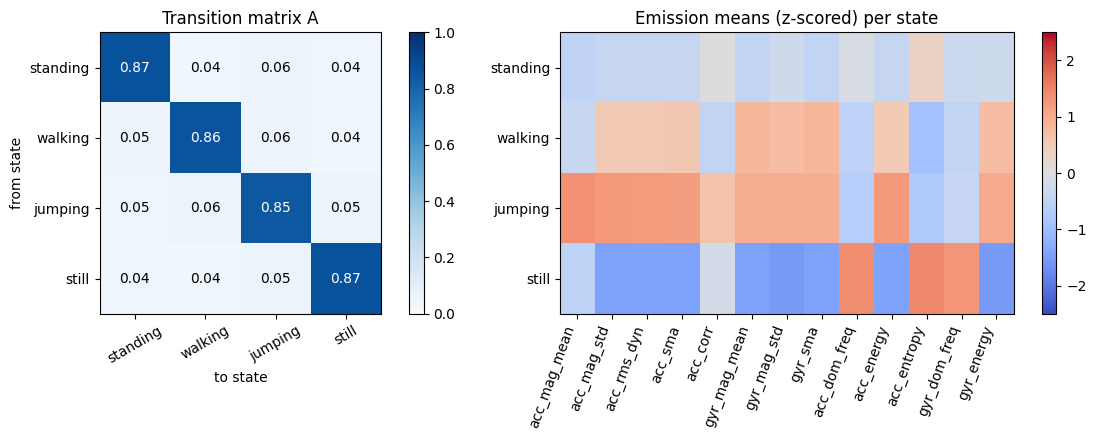

pi = {'standing': np.float64(0.271), 'walking': np.float64(0.354), 'jumping': np.float64(0.167), 'still': np.float64(0.208)}


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
im = ax[0].imshow(hmm.A, cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(K)); ax[0].set_xticklabels(ACTIVITIES, rotation=30); ax[0].set_yticks(range(K)); ax[0].set_yticklabels(ACTIVITIES)
for i in range(K):
    for j in range(K): ax[0].text(j, i, f"{hmm.A[i,j]:.2f}", ha="center", va="center", color="white" if hmm.A[i,j] > .5 else "black")
ax[0].set_xlabel("to state"); ax[0].set_ylabel("from state"); ax[0].set_title("Transition matrix A"); plt.colorbar(im, ax=ax[0])
im2 = ax[1].imshow(hmm.mu, cmap="coolwarm", aspect="auto", vmin=-2.5, vmax=2.5)
ax[1].set_yticks(range(K)); ax[1].set_yticklabels(ACTIVITIES)
ax[1].set_xticks(range(len(FEATURE_NAMES))); ax[1].set_xticklabels(FEATURE_NAMES, rotation=70, ha="right")
ax[1].set_title("Emission means (z-scored) per state"); plt.colorbar(im2, ax=ax[1])
plt.tight_layout(); plt.savefig("fig_transition_emission.png", dpi=150); plt.show()
print("pi =", dict(zip(ACTIVITIES, hmm.pi.round(3))))

## 7. Evaluation on unseen data
Test data = **new continuous sessions** (recorded later, not used in training), where activities are performed one after another.
`sessionN_labels.csv` lists `start,end,label` in seconds so every window gets a ground-truth label (windows whose centre falls outside any labelled segment are dropped).
_Describe in the report: who recorded them, when, where, which phone._

In [25]:
def load_test_session(name):
    rec, fs0 = load_recording(f"{DATA_DIR}/test/{name}.csv")
    lab = pd.read_csv(f"{DATA_DIR}/test/{name}_labels.csv")
    X, centres = featurize(rec)
    # NOTE: load_recording trims TRIM_SEC at the start; centres are already on the trimmed time axis starting at TRIM_SEC
    y = np.full(len(X), -1)
    for _, r in lab.iterrows():
        y[(centres >= r["start"]) & (centres < r["end"])] = ACTIVITIES.index(r["label"].strip().lower())
    keep = y >= 0
    return zscore(X)[keep], y[keep], centres[keep], fs0

TEST_SESSIONS = ["session1", "session2"]
tests = {n: load_test_session(n) for n in TEST_SESSIONS}
for n, (Z, y, c, fs0) in tests.items(): print(n, "windows:", len(y), "orig fs: %.1f Hz" % fs0)

session1 windows: 32 orig fs: 99.4 Hz
session2 windows: 32 orig fs: 99.4 Hz


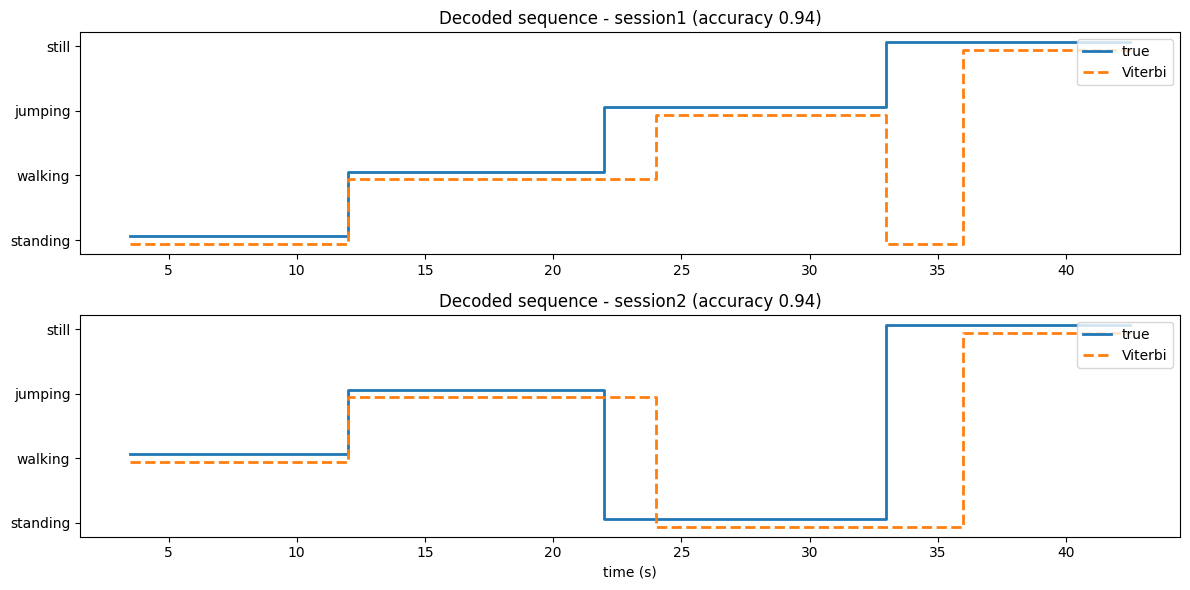

   State  Samples  Sensitivity  Specificity  Accuracy
standing       16        0.938        0.958     0.953
 walking       16        1.000        0.979     0.984
 jumping       16        0.938        0.979     0.969
   still       16        0.875        1.000     0.969

Overall accuracy: 0.938


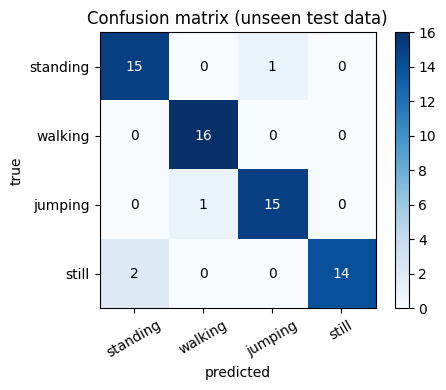

In [26]:
def confusion(y_true, y_pred, k=K):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(y_true, y_pred): cm[t, p] += 1
    return cm

def metrics_table(cm):
    rows, N = [], cm.sum()
    for k in range(K):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append(dict(State=ACTIVITIES[k], Samples=int(cm[k].sum()),
                         Sensitivity=TP / (TP + FN) if TP + FN else np.nan,
                         Specificity=TN / (TN + FP) if TN + FP else np.nan,
                         Accuracy=(TP + TN) / N))
    return pd.DataFrame(rows).round(3)

all_true, all_pred = [], []
fig, axes = plt.subplots(len(tests), 1, figsize=(12, 3 * len(tests)))
axes = np.atleast_1d(axes)
for ax, (n, (Z, y, c, _)) in zip(axes, tests.items()):
    pred = hmm.viterbi(Z); all_true.append(y); all_pred.append(pred)
    ax.step(c, y + 0.06, where="mid", label="true", lw=2); ax.step(c, pred - 0.06, where="mid", label="Viterbi", lw=2, ls="--")
    ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_title(f"Decoded sequence - {n} (accuracy {(pred==y).mean():.2f})"); ax.legend(loc="upper right")
axes[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.savefig("fig_decoded.png", dpi=150); plt.show()

y_true, y_pred = np.concatenate(all_true), np.concatenate(all_pred)
cm = confusion(y_true, y_pred)
print(metrics_table(cm).to_string(index=False))
print("\nOverall accuracy: %.3f" % (np.trace(cm) / cm.sum()))

plt.figure(figsize=(5, 4)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(K), ACTIVITIES, rotation=30); plt.yticks(range(K), ACTIVITIES)
for i in range(K):
    for j in range(K): plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (unseen test data)"); plt.colorbar()
plt.tight_layout(); plt.savefig("fig_confusion.png", dpi=150); plt.show()

## 8. Analysis and reflection

**Easiest and hardest activities.** Walking was the easiest to recognise (sensitivity 1.00, 16 of 16 windows correct), because it has a clear rhythmic pattern: a strong dominant frequency, moderate energy and low spectral entropy. Jumping was also well recognised (sensitivity 0.94). Still was the hardest (sensitivity 0.875): 2 of its 16 windows were predicted as standing, and standing also lost one window to jumping, and jumping one to walking. Overall accuracy on the two unseen sessions was 93.8% (60 of 64 windows). Standing and still are the most similar pair, since in both the phone barely moves. In the emission heatmap their mean feature values are close to each other, and only features such as the dominant frequency, spectral entropy and mean acceleration (which depends on how the phone is oriented) separate them.

**Where the errors happen.** All four errors occurred within about 2 seconds after an activity change, never in the middle of an activity (see the decoded-sequence plot). Each window is 2 s long, so a window that contains the end of one activity and the start of the next looks like a mixture, and the model switches state about one window late. The two still-to-standing errors came from the windows right after I put the phone down, which still contained handling movement. This is a limit of the windowing rather than of the model's ability to tell the activities apart.

**Transition probabilities.** The learned transition matrix has high self-transition probabilities (about 0.85 to 0.87) and small off-diagonal values (about 0.04 to 0.06). This reflects realistic behaviour: activities last several seconds, so with a 1 s step between windows the most likely next state is the same state. This also makes the model smooth out isolated misclassified windows. The off-diagonal values, however, come from how I joined my single-activity recordings in random order for training, so they say little about how people naturally move between activities. For example, a direct change from jumping to still is unlikely in real life. A dataset of continuous, natural behaviour would give more realistic transition probabilities.

**Effect of sensor noise and sampling rate.** My phone recorded at about 99.4 Hz rather than exactly 100 Hz, and the timestamps were not perfectly evenly spaced, so I interpolated everything onto a uniform 50 Hz grid before windowing. 50 Hz is enough for these activities, since walking and jumping movements are below about 5 Hz, and it reduces the data size. Resampling cannot add information the phone did not record, and timing jitter adds a little noise to the FFT-based features. Noise matters most for the still and standing recordings, where the signal is so small that sensor noise and tiny body movements dominate. Because training accuracy was 1.00 and Baum-Welch converged after only 3 iterations, the classes are well separated in feature space in my own data. Note that the model starts from labelled data, so EM only fine-tunes the parameters.

**Possible improvements.** (1) More data: more recordings, different days, places and people, and different phone positions (pocket, hand, bag) would test whether the model generalises beyond one person and one phone. (2) Better test data: my test set was only 64 windows from 2 sessions, and half-overlapping windows are not fully independent, so the metrics have some uncertainty. (3) Extra features such as wavelet coefficients or the magnetometer and barometer could separate standing from still. (4) Shorter or adaptive windows would reduce the delay at activity changes. (5) Emissions with full covariance or Gaussian mixtures would model the features better than the diagonal Gaussians I used, and a duration-aware (semi-Markov) model would describe how long each activity lasts.